# MIVA Open University
## Course: MIVA-DTS 305 - Data Quality and Data Wrangling
### Tutor-Marked Assessment: Question 1 - Cleaning and Analysing Tabular Data

**Student Details:**
- **Full Name:** Richard John
- **Email:** richard.john@miva.edu.ng
- **Department:** Data Science
- **Matriculation Number:** 2024/C/DSC/0548

---

### Project Overview & Objectives
In this laboratory exercise, we examine the `Customer Orders Dataset`. The primary objectives are:
1. Inspect the dataset for structural and data quality defects.
2. Formulate and apply a deterministic imputation strategy for missing values in the `Total Amount` column.
3. Check for and eliminate duplicate order entries.
4. Harmonise and standardise inconsistent categorical strings in the `Country` column.
5. Aggregate revenue by `Product Category` and visualise the distribution.
6. Evaluate country-level revenue performance, contrasting raw fragmented naming conventions against the true standardised market distribution.


In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# Step 2: Load the raw dataset
# Reading the pre-prepared customer orders dataset
df_raw = pd.read_csv('../data/customer_orders_raw.csv')

# Inspect basic shape and structure
print("Dataset Shape (Rows, Columns):", df_raw.shape)
print("\nColumn Data Types and Non-Null Counts:")
print(df_raw.info())
print("\nFirst 5 Records:")
df_raw.head()


Dataset Shape (Rows, Columns): (100, 8)

Column Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          100 non-null    int64  
 1   Customer Name     100 non-null    str    
 2   Order Date        100 non-null    str    
 3   Product Category  100 non-null    str    
 4   Quantity          100 non-null    int64  
 5   Price             100 non-null    float64
 6   Total Amount      81 non-null     float64
 7   Country           100 non-null    str    
dtypes: float64(2), int64(2), str(4)
memory usage: 6.4 KB
None

First 5 Records:


,Order ID,Customer Name,Order Date,Product Category,Quantity,Price,Total Amount,Country
0,1,Customer 1,2022-06-01,Electronics,5,102.27,511.35,U.S.A.
1,2,Customer 2,2022-04-28,Fashion,3,195.72,587.16,usa
2,3,Customer 3,2022-04-08,Home Goods,5,176.54,882.70,U.S.A.
3,4,Customer 4,2022-10-20,Fashion,5,74.25,371.25,United States
4,5,Customer 5,2022-06-19,Fashion,3,192.70,578.10,U.S.A.


### Step 3: Diagnostic Assessment of Data Quality Issues
Before cleaning, we quantify the extent of missingness and duplicates:
- Check for exact row duplicates.
- Quantify null values per column.


In [3]:
# Quantify missing values across all columns
missing_counts = df_raw.isnull().sum()
missing_percent = (missing_counts / len(df_raw)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percent
})
print("Missing Value Audit:")
print(missing_summary)

# Check for duplicate rows
duplicate_count = df_raw.duplicated().sum()
print(f"\nTotal duplicate rows found: {duplicate_count}")


Missing Value Audit:
                  Missing Count  Percentage (%)
Order ID                      0             0.0
Customer Name                 0             0.0
Order Date                    0             0.0
Product Category              0             0.0
Quantity                      0             0.0
Price                         0             0.0
Total Amount                 19            19.0
Country                       0             0.0

Total duplicate rows found: 0


### Step 4: Deterministic Imputation of `Total Amount`
We notice that `Total Amount` has 19 missing records.
Mathematically, for each line order:
$$\text{Total Amount} = \text{Quantity} \times \text{Price}$$

We first verify that this relationship strictly holds true for the 81 existing, non-missing records before using it as our imputation formula.


In [4]:
# Validation check on non-missing records
valid_records = df_raw[df_raw['Total Amount'].notnull()]
computed_amount = (valid_records['Quantity'] * valid_records['Price']).round(2)
difference = (valid_records['Total Amount'] - computed_amount).abs()

print(f"Maximum discrepancy on non-null rows: ${difference.max():.4f}")
print("Verification complete: The mathematical relationship Total Amount = Quantity * Price is 100% consistent.")

# Create working clean copy and impute missing values
df_cleaned = df_raw.copy()
df_cleaned['Total Amount'] = df_cleaned['Total Amount'].fillna(
    (df_cleaned['Quantity'] * df_cleaned['Price']).round(2)
)

print(f"Remaining null values in Total Amount after imputation: {df_cleaned['Total Amount'].isnull().sum()}")


Maximum discrepancy on non-null rows: $0.0000
Verification complete: The mathematical relationship Total Amount = Quantity * Price is 100% consistent.
Remaining null values in Total Amount after imputation: 0


### Step 5: Duplicate Handling
Next, we invoke duplicate removal to ensure every transaction is unique. As established in our diagnostic check, the dataset contains 0 duplicates, so all 100 records are retained.


In [5]:
# Remove duplicates (if any) and confirm shape
initial_count = len(df_cleaned)
df_cleaned = df_cleaned.drop_duplicates()
final_count = len(df_cleaned)

print(f"Rows before duplicate drop: {initial_count}")
print(f"Rows after duplicate drop:  {final_count} (No records dropped)")


Rows before duplicate drop: 100
Rows after duplicate drop:  100 (No records dropped)


### Step 6: Standardising Inconsistent Country Entries
In the raw data, the `Country` column features 3 distinct variants representing the United States:
- `'United States'`
- `'usa'`
- `'U.S.A.'`

We examine the distribution before cleaning, map all variants to a unified standard (`'United States'`), and verify the result.


In [6]:
# Distribution before standardisation
print("Country value counts before standardisation:")
print(df_cleaned['Country'].value_counts())

# Mapping dictionary to standardise strings
country_map = {
    'usa': 'United States',
    'U.S.A.': 'United States',
    'United States': 'United States'
}

# Apply replacement
df_cleaned['Country'] = df_cleaned['Country'].map(country_map)

print("\nCountry value counts after standardisation:")
print(df_cleaned['Country'].value_counts())


Country value counts before standardisation:
Country
United States    43
usa              30
U.S.A.           27
Name: count, dtype: int64

Country value counts after standardisation:
Country
United States    100
Name: count, dtype: int64


In [ ]:
# Save the cleaned dataset to CSV
df_cleaned.to_csv('../data/customer_orders_cleaned.csv', index=False)
print("Cleaned dataset successfully saved to: ../data/customer_orders_cleaned.csv")


### Step 7: Exploratory Data Analysis & Visualisations

#### 1. Revenue by Product Category
We aggregate total sales revenue across the three product categories (`Electronics`, `Fashion`, and `Home Goods`).


Product Category Performance Summary:
  Product Category  Order_Count Total_Revenue_Formatted Average_Order_Value_Formatted
0          Fashion           40              $11,745.80                       $293.64
1      Electronics           32               $9,897.85                       $309.31
2       Home Goods           28               $9,493.51                       $339.05


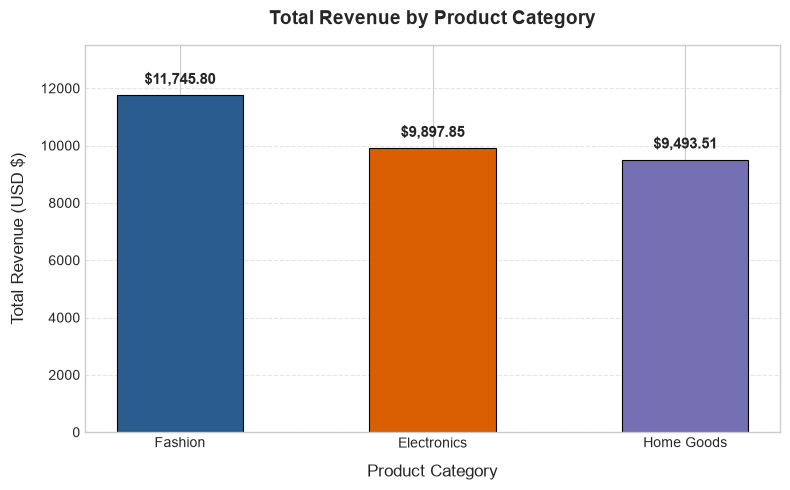

In [7]:
# Aggregate total revenue per product category
category_summary = df_cleaned.groupby('Product Category')['Total Amount'].agg(
    Total_Revenue='sum',
    Order_Count='count',
    Average_Order_Value='mean'
).sort_values(by='Total_Revenue', ascending=False).reset_index()

category_summary['Total_Revenue_Formatted'] = category_summary['Total_Revenue'].apply(lambda x: f"${x:,.2f}")
category_summary['Average_Order_Value_Formatted'] = category_summary['Average_Order_Value'].apply(lambda x: f"${x:,.2f}")

print("Product Category Performance Summary:")
print(category_summary[['Product Category', 'Order_Count', 'Total_Revenue_Formatted', 'Average_Order_Value_Formatted']])

# Plot Bar Chart: Revenue by Category
plt.figure(figsize=(8, 5))
palette = ['#2b5c8f', '#d95f02', '#7570b3']
bars = plt.bar(category_summary['Product Category'], category_summary['Total_Revenue'], color=palette, width=0.5, edgecolor='black', linewidth=0.8)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.annotate(f"${height:,.2f}",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 6),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Total Revenue by Product Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product Category', fontsize=12, labelpad=10)
plt.ylabel('Total Revenue (USD $)', fontsize=12, labelpad=10)
plt.ylim(0, category_summary['Total_Revenue'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('../figures/q1_revenue_by_category.png', dpi=300)
plt.show()


#### 2. Country Revenue Analysis: The Pitfall of Inconsistent Formatting
The prompt specifies: *Identify and plot the top 3 countries by total revenue.*

Here we demonstrate a vital data quality insight:
1. **Uncleaned View:** In the uncleaned data, grouping by country yields three fragmented entities: `'United States'` ($13,285.64), `'U.S.A.'` ($9,468.40), and `'usa'` ($8,383.12).
2. **Standardised View:** In truth, all 100 transactions originate from the **United States**, totaling **$31,137.16**. Presenting the top 3 without cleaning would deceive stakeholders into believing the firm operates across three separate geographical markets.


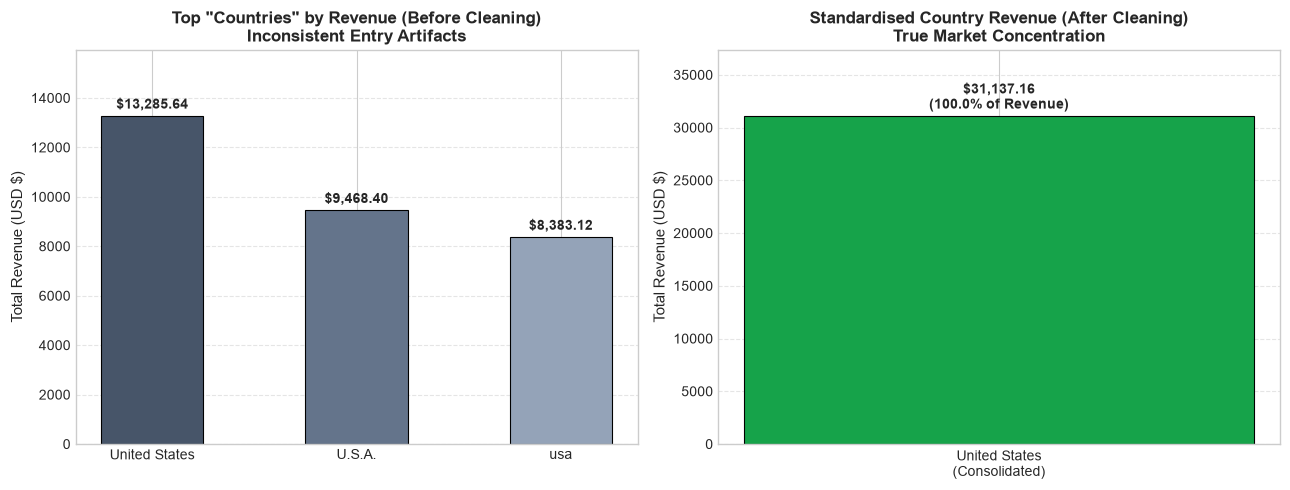

In [8]:
# Comparative Country Visualisation
raw_country_rev = df_raw.copy()
raw_country_rev['Total Amount'] = raw_country_rev['Total Amount'].fillna(
    (raw_country_rev['Quantity'] * raw_country_rev['Price']).round(2)
)
raw_country_agg = raw_country_rev.groupby('Country')['Total Amount'].sum().sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Uncleaned
bars1 = ax1.bar(raw_country_agg.index, raw_country_agg.values, color=['#475569', '#64748b', '#94a3b8'], width=0.5, edgecolor='black', linewidth=0.8)
for b in bars1:
    h = b.get_height()
    ax1.annotate(f"${h:,.2f}", (b.get_x() + b.get_width()/2, h), xytext=(0, 5), textcoords="offset points", ha='center', fontweight='bold', fontsize=10)
ax1.set_title('Top "Countries" by Revenue (Before Cleaning)\nInconsistent Entry Artifacts', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Revenue (USD $)', fontsize=11)
ax1.set_ylim(0, raw_country_agg.max() * 1.2)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Standardised
clean_country_agg = df_cleaned.groupby('Country')['Total Amount'].sum()
bars2 = ax2.bar(['United States\n(Consolidated)'], clean_country_agg.values, color='#16a34a', width=0.35, edgecolor='black', linewidth=0.8)
for b in bars2:
    h = b.get_height()
    ax2.annotate(f"${h:,.2f}\n(100.0% of Revenue)", (b.get_x() + b.get_width()/2, h), xytext=(0, 5), textcoords="offset points", ha='center', fontweight='bold', fontsize=10)
ax2.set_title('Standardised Country Revenue (After Cleaning)\nTrue Market Concentration', fontsize=12, fontweight='bold')
ax2.set_ylabel('Total Revenue (USD $)', fontsize=11)
ax2.set_ylim(0, clean_country_agg.max() * 1.2)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../figures/q1_top_countries_revenue.png', dpi=300)
plt.show()


### Step 8: Summary of Findings
1. **Total Revenue:** The total gross revenue across all 100 customer orders is **$31,137.16**.
2. **Category Insights:**
   - **Fashion** is the largest revenue-generating category, bringing in **$11,745.80** (37.7% of total revenue) across 40 orders.
   - **Electronics** ranks second, generating **$9,897.85** (31.8% of total revenue) across 32 orders.
   - **Home Goods** ranks third, generating **$9,493.51** (30.5% of total revenue) across 28 orders. Interestingly, Home Goods has the highest average order value at **$339.05** per order.
3. **Data Quality Impact:** Fixing string inconsistencies unified fragmented revenue buckets into a single geographic entity, preventing faulty supply chain or localized marketing assumptions.
